# Day 32/100 — RicePest Spotter 🐛 | Reproducible YOLO Object Detection + Counting

**Problem:** Farmers and extension workers need an initial indication of visible pest objects in field photos. **MVP:** photo → bounding boxes, class, estimated count. A detector is *not* an exhaustive census or crop disease diagnosis.

**Input mounted by user:** `/kaggle/input/datasets/wafabila/ricepest-dataset` (RicePest-30 cleaned version). This notebook **does not download or manufacture training images**. It discovers the supplied COCO annotations, verifies integrity, converts actual annotations, trains an official pretrained Ultralytics YOLO detector, evaluates only on the provided validation set, and packages real run outputs. A truly independent held-out test set does not exist in the supplied cleaned package.

**Run instructions:** Kaggle GPU T4 (or P100), Internet **ON** for Ultralytics installation/pretrained weights; `Run All` → `Save Version`. No claimed accuracy before the cells execute.

**Sources:** [RicePest-30 official repository](https://github.com/kkb20334-lang/RicePest-30) (CC BY-NC 4.0, research/noncommercial conditions), [Ultralytics Python API](https://docs.ultralytics.com/usage/python/), [YOLO validation API](https://docs.ultralytics.com/modes/val/). Keep Kaggle dataset private unless redistribution is permitted. Check package/license terms before any publication or commercial deployment.

**Revision V3 (2026-11-04):** 300 source images have unsafe COCO-vs-file aspect ratios; quarantine these source images and every associated annotation rather than invent bbox corrections. Train/evaluate only on the audited, eligible subset. Source split assignment is unchanged. All exclusions are enumerated in the archive.


## 0 — Environment, version checks & deterministic settings

In [1]:
%pip -q install "ultralytics>=8.3,<9" "pyyaml>=6" "Pillow>=10"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, json, csv, hashlib, shutil, random, math, time, warnings, subprocess, importlib.metadata
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np, pandas as pd, cv2, yaml, torch
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display
from ultralytics import YOLO

SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
assert torch.cuda.is_available(), 'GPU not enabled: Kaggle Settings > Accelerator > GPU'
SOURCE=Path('/kaggle/input/datasets/wafabila/ricepest-dataset')
assert SOURCE.is_dir(), f'Missing Add Input: {SOURCE}'
WORK=Path('/kaggle/working/Day32_RicePest_Spotter')
YOLO_DATA=WORK/'yolo_dataset';AUDIT=WORK/'audit'; REPORTS=WORK/'reports';PLOTS=WORK/'plots';DEMO=WORK/'demo';MODELS=WORK/'models'
for p in (YOLO_DATA,AUDIT,REPORTS,PLOTS,DEMO,MODELS):p.mkdir(parents=True,exist_ok=True)
CONFIG=dict(seed=SEED,weights='yolo11n.pt',epochs=65,patience=15,imgsz=640,batch=16,device=0,workers=2,conf_threshold=0.25,iou_threshold=0.65)
print('Python',sys.version.split()[0],'PyTorch',torch.__version__,'CUDA',torch.cuda.get_device_name(0))
print('Ultralytics',importlib.metadata.version('ultralytics'))
print('Input',SOURCE)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python 3.13.16 PyTorch 2.11.0+cu130 CUDA Tesla T4
Ultralytics 8.4.202
Input /kaggle/input/datasets/wafabila/ricepest-dataset


## 1 — Find and validate the **actual** COCO training/validation files

In [3]:
# Data-driven discovery; refuses to guess if multiple candidates cannot be distinguished.
def read_coco(p):
    try:
        with p.open('r',encoding='utf-8-sig') as f: obj=json.load(f)
        if isinstance(obj,dict) and all(isinstance(obj.get(k),list) for k in ('images','annotations','categories')):
            return obj
    except (OSError,UnicodeError,ValueError):pass
    return None

candidates=[]
for p in sorted(SOURCE.rglob('*.json')):
    if any(x in p.parts for x in ('.git','__MACOSX')):continue
    obj=read_coco(p)
    if obj is not None:
        low='/'.join(part.lower() for part in p.parts)
        guess=('val' if ('/val/' in low or '/valid/' in low or 'validation' in low) else
               'train' if '/train/' in low or 'training' in low else 'unknown')
        candidates.append((p,obj,guess))
print('COCO files:',[(str(p.relative_to(SOURCE)),g,len(d['images']),len(d['annotations'])) for p,d,g in candidates])
selected={}
for split in ('train','val'):
    choices=[(p,d) for p,d,g in candidates if g==split]
    assert len(choices)==1, f'Expected exactly one {split} COCO annotation; got {len(choices)}. Check inventory above.'
    selected[split]=choices[0]
assert selected['train'][0]!=selected['val'][0]

stats=[]
for split,(p,data) in selected.items():
    imgs=data['images'];anns=data['annotations'];cats=data['categories']
    img_ids=[i['id'] for i in imgs];cat_ids=[c['id'] for c in cats]
    assert len(img_ids)==len(set(img_ids)),f'Duplicate image IDs: {split}'
    assert len(cat_ids)==len(set(cat_ids)),f'Duplicate category IDs: {split}'
    assert len(imgs)>0 and len(anns)>0 and len(cats)>1
    assert all('file_name' in im and 'width' in im and 'height' in im for im in imgs)
    image_id_set=set(img_ids);category_id_set=set(cat_ids)
    assert all(a.get('image_id') in image_id_set for a in anns),f'Orphan annotation {split}'
    assert all(a.get('category_id') in category_id_set for a in anns),f'Unknown annotation category {split}'
    stats.append(dict(split=split,coco_file=str(p),images=len(imgs),annotations=len(anns),categories=len(cats)))
show=pd.DataFrame(stats);display(show)
show.to_csv(AUDIT/'source_counts.csv',index=False)


COCO files: [('RicePest-30/train/annotations_coco_clean.json', 'train', 7915, 55338), ('RicePest-30/val/annotations_coco_clean.json', 'val', 654, 4843)]


,split,coco_file,images,annotations,categories
0,train,/kaggle/input/datasets/wafabila/ricepest-datas...,7915,55338,30
1,val,/kaggle/input/datasets/wafabila/ricepest-datas...,654,4843,30


## 2 — Category audit: preserve **ID identity**, including duplicate human-readable names

In [4]:
train_cats={int(c['id']):str(c['name']).strip() for c in selected['train'][1]['categories']}
val_cats={int(c['id']):str(c['name']).strip() for c in selected['val'][1]['categories']}
assert train_cats==val_cats, 'train/val category ID mappings differ; stop and audit; do not remap automatically'
all_ids=sorted(train_cats)
assert len(all_ids)==30, f'Expected 30 source category IDs, got {len(all_ids)}'
name_counts=Counter(train_cats.values())
duplicate_names={name:ct for name,ct in name_counts.items() if ct>1}
print('Duplicate category display names:',duplicate_names)
# Keep separate official IDs; merging same names without ontology evidence could corrupt labels.
names=[train_cats[k]+(f' [source_id={k}]' if name_counts[train_cats[k]]>1 else '') for k in all_ids]
assert len(names)==len(set(names))
id_to_yolo={k:i for i,k in enumerate(all_ids)}
classes=pd.DataFrame([{'source_category_id':k,'yolo_id':id_to_yolo[k], 'original_name':train_cats[k], 'model_name':names[id_to_yolo[k]]} for k in all_ids])
classes.to_csv(AUDIT/'class_id_mapping.csv',index=False)
display(classes)
(REPORTS/'ontology_warning.txt').write_text('Source category IDs deliberately kept separate even if their display names match. Inspect ambiguous categories before any real-world species-level claims.\n',encoding='utf8')


Duplicate category display names: {'Anomala corpulenta': 2}


,source_category_id,yolo_id,original_name,model_name
0,1,0,Ostrinia furnacalis,Ostrinia furnacalis
1,2,1,Chilo suppressalis,Chilo suppressalis
2,3,2,Cnaphalocrocis medinalis,Cnaphalocrocis medinalis
3,4,3,Scirpophaga incertulas,Scirpophaga incertulas
4,5,4,Spodoptera frugiperda,Spodoptera frugiperda
5,6,5,Spodoptera spp.,Spodoptera spp.
6,7,6,Sesamia inferens,Sesamia inferens
7,8,7,Agrotis ipsilon,Agrotis ipsilon
8,9,8,Anomala corpulenta,Anomala corpulenta [source_id=9]
9,10,9,Holotrichia diomphalia,Holotrichia diomphalia


155

## 3 — Integrity audit, SAFE aspect-ratio eligibility & leakage checks

- **Confirmed from V2 Kaggle execution:** 7,750 images differ in pixel size from COCO metadata, of which 300 have >2% aspect mismatch. A resize with unchanged aspect ratio is safe to normalize using original COCO canvas; substantially differing ratios may indicate cropping or wrong metadata.
- Such ambiguous images are **excluded from both images and annotations** in V3, with image IDs, paths, reason and excluded annotation counts recorded. Do not "fix" them by stretching bounding boxes.
- Remaining images must be readable, have positive dimensions, and pass the 2% relative aspect-ratio tolerance. Training is intentionally on a documented eligible subset, **not all source images**.
- This is not an independent test; validation subset can have selection bias from filtering.


In [5]:
IMAGE_EXT={'.jpg','.jpeg','.png','.bmp','.webp'}
image_files=[p for p in SOURCE.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXT]
by_name=defaultdict(list)
for p in image_files: by_name[p.name].append(p)
print('Files with image extensions:',len(image_files))

def resolve_image(im,annotation_file,split):
    relative=str(im['file_name']).replace(chr(92),'/').lstrip('/')
    if '..' in Path(relative).parts: raise RuntimeError('Path traversal in COCO file_name')
    p=Path(relative)
    tries=[annotation_file.parent/p,annotation_file.parent/'images'/p,SOURCE/p,
           SOURCE/split/p,SOURCE/split/'images'/p]
    for t in tries:
        if t.is_file():return t.resolve()
    matches=by_name.get(p.name,[])
    if len(matches)==1:return matches[0].resolve()
    matches=[x for x in matches if split in [z.lower() for z in x.parts]]
    if len(matches)==1:return matches[0].resolve()
    raise FileNotFoundError(f'Cannot uniquely resolve {split} image: {relative}, candidates={len(matches)}')

# Never hide dropped examples: maintain immutable source image IDs and reasons.
ASPECT_TOLERANCE=0.02
records={}; exclusions=[];dim_diffs=[]; audit_counts={}
for split,(annotation_file,data) in selected.items():
    recs=[]
    for im in data['images']:
        common={'split':split,'image_id':im.get('id'),'file_name':str(im.get('file_name'))}
        try:
            imgpath=resolve_image(im,annotation_file,split)
            with Image.open(imgpath) as image:
                actual_w,actual_h=image.size
                image.verify()
            coco_w,coco_h=int(im['width']),int(im['height'])
            if min(actual_w,actual_h,coco_w,coco_h)<=0: raise ValueError('nonpositive dimensions')
            aspect_error=abs((actual_w/actual_h)/(coco_w/coco_h)-1)
            if (actual_w,actual_h)!=(coco_w,coco_h):
                dim_diffs.append({**common,'actual_width':actual_w,'actual_height':actual_h,
                                  'coco_width':coco_w,'coco_height':coco_h,'aspect_error':aspect_error})
            if aspect_error>ASPECT_TOLERANCE:
                exclusions.append({**common,'reason':'aspect_ratio_mismatch','detail':
                     f'COCO {coco_w}x{coco_h} vs file {actual_w}x{actual_h}, error={aspect_error:.3%}'})
                continue
            recs.append({**common,'source_path':str(imgpath),'width':coco_w,'height':coco_h,
                         'actual_width':actual_w,'actual_height':actual_h,'aspect_ratio_error':aspect_error})
        except (OSError,ValueError,FileNotFoundError,RuntimeError) as exc:
            exclusions.append({**common,'reason':'unreadable_or_unresolved','detail':str(exc)})
    records[split]=pd.DataFrame(recs)
    assert len(records[split]), f'All {split} images excluded; check source integrity'
    audit_counts[split]={'source_images':len(data['images']),'eligible_images':len(recs),
                         'excluded_images':len(data['images'])-len(recs)}

excluded=pd.DataFrame(exclusions,columns=['split','image_id','file_name','reason','detail'])
excluded.to_csv(AUDIT/'excluded_source_images.csv',index=False)
pd.DataFrame(dim_diffs,columns=['split','image_id','file_name','actual_width','actual_height',
        'coco_width','coco_height','aspect_error']).to_csv(AUDIT/'dimension_mismatch_audit.csv',index=False)
pd.DataFrame(audit_counts).T.to_csv(AUDIT/'eligibility_counts.csv')
assert sum(x['eligible_images']+x['excluded_images'] for x in audit_counts.values())==sum(len(d['images']) for _,d in selected.values())
print('Eligible source image counts:',audit_counts)
print('Dimension mismatches:',len(dim_diffs),'excluded:',len(exclusions))
print('Exclusion reasons:',excluded.reason.value_counts().to_dict() if len(excluded) else {})
if len(excluded): display(excluded.head(12))

# Explicit train/val exact-image leakage audit, after eligibility filtering.
def filehash(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(2*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
for split in ('train','val'):
    records[split]['sha256']=[filehash(x) for x in records[split].source_path]
train_hashes=set(records['train'].sha256);val_hashes=set(records['val'].sha256)
overlap=train_hashes&val_hashes
print('Cross-split SHA256 exact duplicate hashes:',len(overlap))
if overlap:
    pd.concat([records[s][records[s].sha256.isin(overlap)] for s in ('train','val')]).to_csv(
        AUDIT/'cross_split_hash_leakage.csv',index=False)
    raise RuntimeError('Exact train/val duplicate leakage; inspect cross_split_hash_leakage.csv')
for split in ('train','val'):
    records[split].to_csv(AUDIT/f'{split}_image_manifest.csv',index=False)
print('[PASS] Eligible images audited; ambiguous crops excluded, source splits unchanged')
print('LIMITATION: Near-duplicates were not comprehensively audited, and exclusion may bias validation.')

Files with image extensions: 8569
Eligible source image counts: {'train': {'source_images': 7915, 'eligible_images': 7623, 'excluded_images': 292}, 'val': {'source_images': 654, 'eligible_images': 646, 'excluded_images': 8}}
Dimension mismatches: 7750 excluded: 300
Exclusion reasons: {'aspect_ratio_mismatch': 300}


,split,image_id,file_name,reason,detail
0,train,2967,2967_cdtye_1.jpg,aspect_ratio_mismatch,"COCO 4080x3060 vs file 117x180, error=51.250%"
1,train,2968,2968_cdtye_10.jpg,aspect_ratio_mismatch,"COCO 4080x3060 vs file 277x184, error=12.908%"
2,train,2979,2979_cdtye_11.jpg,aspect_ratio_mismatch,"COCO 4080x3060 vs file 116x184, error=52.717%"
3,train,2990,2990_cdtye_12.jpg,aspect_ratio_mismatch,"COCO 4080x3060 vs file 254x180, error=5.833%"
4,train,3001,3001_cdtye_13.jpg,aspect_ratio_mismatch,"COCO 4080x3060 vs file 267x180, error=11.250%"
5,train,3012,3012_cdtye_14.jpg,aspect_ratio_mismatch,"COCO 4080x3060 vs file 192x180, error=20.000%"
6,train,3023,3023_cdtye_15.jpg,aspect_ratio_mismatch,"COCO 3060x4080 vs file 151x180, error=11.852%"
7,train,3034,3034_cdtye_16.jpg,aspect_ratio_mismatch,"COCO 3060x4080 vs file 176x180, error=30.370%"
8,train,3045,3045_cdtye_17.jpg,aspect_ratio_mismatch,"COCO 3060x4080 vs file 191x180, error=41.481%"
9,train,3056,3056_cdtye_18.jpg,aspect_ratio_mismatch,"COCO 3060x4080 vs file 193x180, error=42.963%"


Cross-split SHA256 exact duplicate hashes: 0
[PASS] Eligible images audited; ambiguous crops excluded, source splits unchanged
LIMITATION: Near-duplicates were not comprehensively audited, and exclusion may bias validation.


## 4 — COCO → YOLO, preserving only eligible source images and their own boxes

Excluded image IDs are NEVER treated as empty-background images, and **all of their COCO annotations are excluded**, with counts recorded. Eligible images are normalized in the original COCO coordinate system only when aspect ratio is consistent. This protects against the 300 unsafe crops identified by V2.


In [6]:
# Prepare source-safe YOLO training dataset (no fabricated labels).
# Every excluded image also loses *all* its linked COCO annotation objects.
for split in ('train','val'):
    (YOLO_DATA/'images'/split).mkdir(parents=True,exist_ok=True)
    (YOLO_DATA/'labels'/split).mkdir(parents=True,exist_ok=True)

box_reports=[];summary={};excluded_box_rows=[]
for split,(annpath,coco) in selected.items():
    good_ids=set(records[split]['image_id'])
    by_id={k:[] for k in good_ids}
    excluded_ann_count=Counter()
    for ann in coco['annotations']:
        if ann['image_id'] in good_ids:
            by_id[ann['image_id']].append(ann)
        else:
            excluded_ann_count[ann['image_id']]+=1
    for image_id,count in excluded_ann_count.items():
        excluded_box_rows.append({'split':split,'image_id':image_id,'annotations_excluded':count})

    output_count=0;dropped=0;clipped=0;crowds=0
    for r in records[split].itertuples(index=False):
        src=Path(r.source_path)
        tag=f'{str(r.image_id).replace("-","_")}_{hashlib.sha256(str(src).encode()).hexdigest()[:12]}'
        suffix=src.suffix.lower()
        target_image=YOLO_DATA/'images'/split/(tag+suffix)
        target_label=YOLO_DATA/'labels'/split/(tag+'.txt')
        if not target_image.exists():
            try:target_image.symlink_to(src)
            except (OSError,NotImplementedError):shutil.copy2(src,target_image)
        lines=[]
        for ann in by_id[r.image_id]:
            bbox=ann.get('bbox',None)
            if not isinstance(bbox,(list,tuple)) or len(bbox)!=4:
                raise RuntimeError(f'Invalid bbox: {split} ann {ann.get("id")}')
            x,y,w,h=map(float,bbox)
            if not all(map(math.isfinite,(x,y,w,h))):raise RuntimeError('Nonfinite bbox')
            if int(ann.get('iscrowd',0))!=0:
                crowds+=1;box_reports.append(dict(split=split,ann_id=ann.get('id'),reason='iscrowd_skip'));continue
            if w<=0 or h<=0:
                dropped+=1;box_reports.append(dict(split=split,ann_id=ann.get('id'),reason='nonpositive_width_height'));continue
            x1=max(0.,min(float(r.width),x));y1=max(0.,min(float(r.height),y))
            x2=max(0.,min(float(r.width),x+w));y2=max(0.,min(float(r.height),y+h))
            if x2<=x1 or y2<=y1:
                dropped+=1;box_reports.append(dict(split=split,ann_id=ann.get('id'),reason='out_of_bounds'));continue
            if any(abs(a-b)>1e-5 for a,b in zip((x1,y1,x2,y2),(x,y,x+w,y+h))):clipped+=1
            cid=id_to_yolo[int(ann['category_id'])]
            xc=(x1+x2)/2/r.width;yc=(y1+y2)/2/r.height;bw=(x2-x1)/r.width;bh=(y2-y1)/r.height
            assert all(0<=v<=1+1e-6 for v in (xc,yc,bw,bh))
            lines.append(f'{cid} {xc:.8f} {yc:.8f} {bw:.8f} {bh:.8f}')
        target_label.write_text(('\n'.join(lines)+'\n') if lines else '',encoding='utf8')
        output_count+=len(lines)
    summary[split]={'source_images':len(coco['images']),'eligible_images':len(records[split]),
       'excluded_images':len(coco['images'])-len(records[split]),
       'source_annotations':len(coco['annotations']),
       'excluded_annotations_due_to_unsafe_images':sum(excluded_ann_count.values()),
       'boxes':output_count,'dropped_boxes_from_eligible':dropped,
       'clipped_boxes_from_eligible':clipped,'skipped_crowd_from_eligible':crowds}

pd.DataFrame(excluded_box_rows,columns=['split','image_id','annotations_excluded']).to_csv(AUDIT/'excluded_annotations_by_image.csv',index=False)
pd.DataFrame(box_reports,columns=['split','ann_id','reason']).to_csv(AUDIT/'bbox_issues_eligible.csv',index=False)
for split in ('train','val'):
    s=summary[split]
    assert s['source_annotations']==s['excluded_annotations_due_to_unsafe_images']+s['boxes']+s['dropped_boxes_from_eligible']+s['skipped_crowd_from_eligible']
    if s['dropped_boxes_from_eligible']+s['skipped_crowd_from_eligible']:
        raise RuntimeError('Invalid boxes/crowd in eligible images: inspect audit/bbox_issues_eligible.csv')
    assert s['boxes']>0

config={'path':str(YOLO_DATA),'train':'images/train','val':'images/val','nc':len(names),'names':names}
DATA_YAML=YOLO_DATA/'data.yaml'
DATA_YAML.write_text(yaml.safe_dump(config,sort_keys=False,allow_unicode=True),encoding='utf8')
(AUDIT/'conversion_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf8')
print('Audited YOLO dataset:',json.dumps(summary,indent=2))
print('[PASS] Exclusions are explicit; COCO/YOLO box conservation verified')

Audited YOLO dataset: {
  "train": {
    "source_images": 7915,
    "eligible_images": 7623,
    "excluded_images": 292,
    "source_annotations": 55338,
    "excluded_annotations_due_to_unsafe_images": 292,
    "boxes": 55046,
    "dropped_boxes_from_eligible": 0,
    "clipped_boxes_from_eligible": 0,
    "skipped_crowd_from_eligible": 0
  },
  "val": {
    "source_images": 654,
    "eligible_images": 646,
    "excluded_images": 8,
    "source_annotations": 4843,
    "excluded_annotations_due_to_unsafe_images": 8,
    "boxes": 4835,
    "dropped_boxes_from_eligible": 0,
    "clipped_boxes_from_eligible": 0,
    "skipped_crowd_from_eligible": 0
  }
}
[PASS] Exclusions are explicit; COCO/YOLO box conservation verified


## 5 — Visual sanity check: real image + converted ground-truth boxes

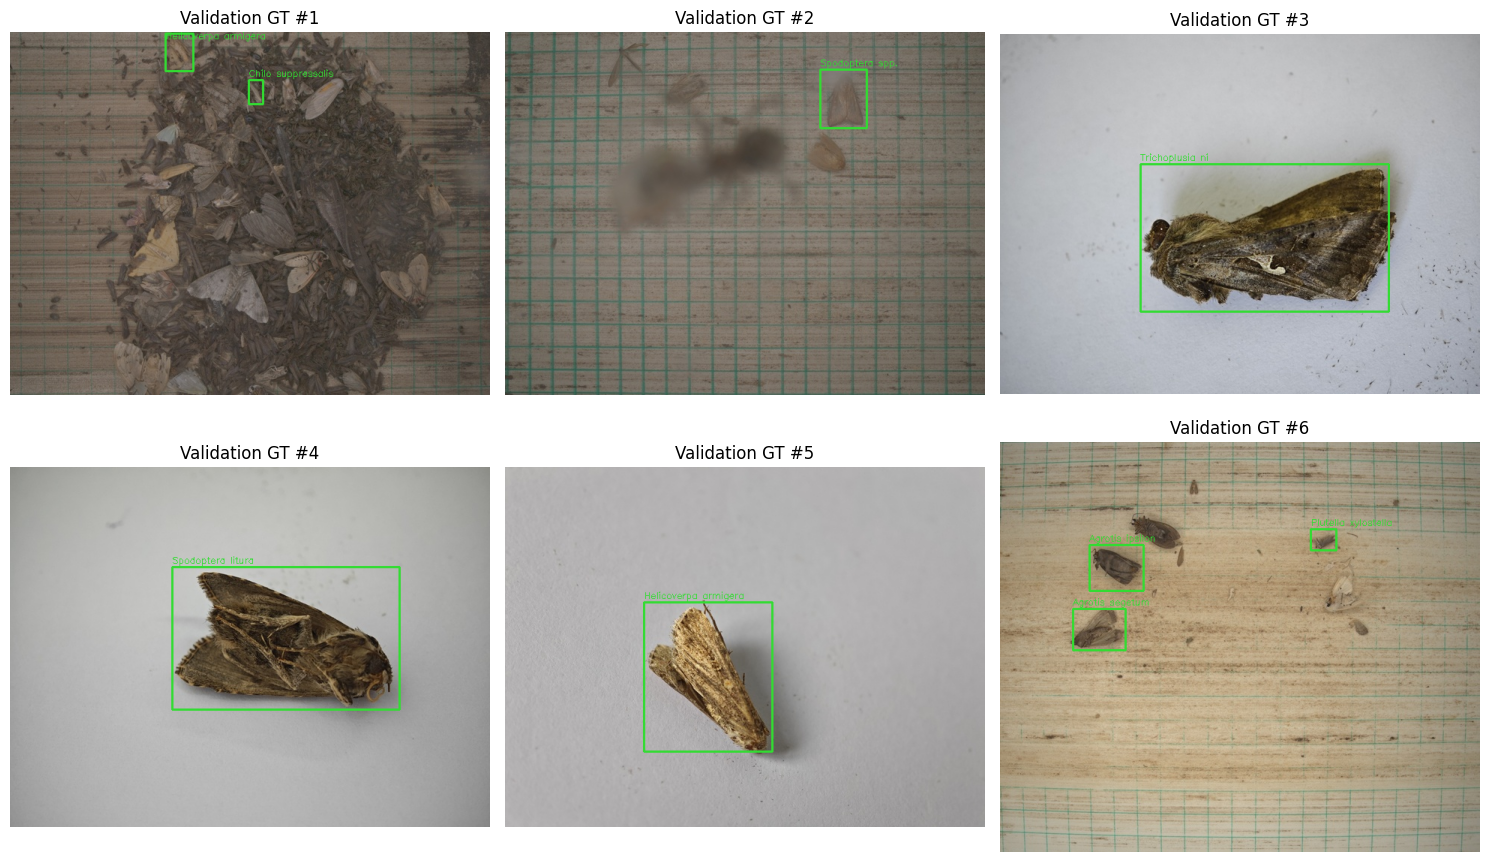

In [7]:
def draw_labels(image_path,label_path):
    im=cv2.imread(str(image_path));assert im is not None
    h,w=im.shape[:2]
    for line in label_path.read_text().splitlines():
        a=line.split();cid=int(a[0]);xc,yc,bw,bh=map(float,a[1:])
        x1=int((xc-bw/2)*w);x2=int((xc+bw/2)*w);y1=int((yc-bh/2)*h);y2=int((yc+bh/2)*h)
        cv2.rectangle(im,(x1,y1),(x2,y2),(50,220,50),2)
        cv2.putText(im,names[cid][:24],(max(x1,0),max(y1-5,10)),cv2.FONT_HERSHEY_SIMPLEX,.40,(50,220,50),1)
    return cv2.cvtColor(im,cv2.COLOR_BGR2RGB)

sample_images=sorted((YOLO_DATA/'images'/'val').glob('*'))
assert sample_images
rng=random.Random(SEED)
chosen=rng.sample(sample_images,min(6,len(sample_images)))
fig,axes=plt.subplots(2,3,figsize=(15,9));axes=axes.ravel()
for j,ax in enumerate(axes):
    if j<len(chosen):
        im=chosen[j];label=YOLO_DATA/'labels'/'val'/(im.stem+'.txt')
        ax.imshow(draw_labels(im,label));ax.set_title(f'Validation GT #{j+1}')
    ax.axis('off')
plt.tight_layout();plt.savefig(PLOTS/'ground_truth_grid.png',dpi=130);plt.show();plt.close()


## 6 — Train pretrained YOLO11 nano (reproducible baseline, not claimed SOTA)

In [8]:
# Only train + val are available. NO test performance is asserted.
# Runtime depends on Kaggle GPU. We use 65 epochs max / early stopping and official pretrained weights.
assert DATA_YAML.is_file()
try:
    detector=YOLO(CONFIG['weights'])
except Exception as e:
    raise RuntimeError('Pretrained weights unavailable. Enable Kaggle Internet or attach the official weights as a model input.') from e
run=detector.train(
    data=str(DATA_YAML),epochs=CONFIG['epochs'],patience=CONFIG['patience'],
    imgsz=CONFIG['imgsz'],batch=CONFIG['batch'],device=CONFIG['device'],workers=CONFIG['workers'],
    seed=SEED,deterministic=True,pretrained=True,optimizer='auto',amp=True,
    cache=False,plots=True,project=str(WORK/'train_runs'),name='yolo11n_baseline',exist_ok=True,
    degrees=5,translate=.08,scale=.4,fliplr=.5,mosaic=1.,close_mosaic=10,
    val=True,save=True,verbose=True
)
RUN_DIR=Path(detector.trainer.save_dir)
BEST=RUN_DIR/'weights'/'best.pt';LAST=RUN_DIR/'weights'/'last.pt'
assert BEST.is_file() and BEST.stat().st_size>1_000_000, 'best.pt missing; do not report training success'
shutil.copy2(BEST,MODELS/'best.pt')
if LAST.is_file():shutil.copy2(LAST,MODELS/'last.pt')
print('[TRAIN COMPLETED]',BEST)


Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Day32_RicePest_Spotter/yolo_dataset/data.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=65, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_baseline, nbs=64, nms=

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/65      3.55G       1.64      2.005      1.225         53        640: 100% ━━━━━━━━━━━━ 477/477 7.7it/s 1:02
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 5.4it/s 3.9s
                   all        646       4835      0.519      0.413      0.406       0.24

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/65      3.77G        1.6      1.749      1.213         54        640: 100% ━━━━━━━━━━━━ 477/477 7.7it/s 1:02
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 5.5it/s 3.8s
                   all        646       4835      0.506      0.464      0.454      0.262

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/65      3.77G       1.57      1.612      1.198         50        640: 100% ━━━━━━━━━━━━ 477/477 7.7it/s 1:02
                 Class     Images  Instances      Box(P 

## 7 — Locked best model: validation mAP, precision, recall, per-class AP

In [9]:
best=YOLO(str(MODELS/'best.pt'))
metrics=best.val(data=str(DATA_YAML),split='val',imgsz=CONFIG['imgsz'],batch=CONFIG['batch'],device=0,
                 plots=True,conf=.001,iou=.7,project=str(WORK/'validation_runs'),name='best_val',exist_ok=True)
box=metrics.box
scores={'precision':float(box.mp),'recall':float(box.mr),'mAP50':float(box.map50),'mAP50_95':float(box.map),
        'n_train_images':int(summary['train']['eligible_images']),'n_val_images':int(summary['val']['eligible_images']),
        'test_set_available':False,'model':'yolo11n.pt fine-tuned','metrics_split':'validation'}
(REPORTS/'validation_metrics.json').write_text(json.dumps(scores,indent=2),encoding='utf8')
per_ap=np.asarray(box.maps,dtype=float)
pd.DataFrame([{'yolo_id':i,'source_id':all_ids[i],'name':names[i],'val_mAP50_95':float(per_ap[i])} for i in range(len(names))]).to_csv(REPORTS/'per_class_map.csv',index=False)
print(json.dumps(scores,indent=2));display(pd.read_csv(REPORTS/'per_class_map.csv'))


Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,604,098 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 293.2±85.5 MB/s, size: 137.0 KB)
val: Scanning /kaggle/working/Day32_RicePest_Spotter/yolo_dataset/labels/val.cache... 646 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 646/646 246.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 7.1it/s 5.8s
                   all        646       4835       0.74      0.625      0.698      0.434
   Ostrinia furnacalis         59        105      0.508      0.457       0.44      0.253
    Chilo suppressalis        191       1288       0.81      0.814      0.877      0.509
Cnaphalocrocis medinalis        105        600      0.787       0.66      0.783       0.41
Scirpophaga incertulas         35         42      0.723      0.238      0.396      0.218
 Spodopter

,yolo_id,source_id,name,val_mAP50_95
0,0,1,Ostrinia furnacalis,0.252848
1,1,2,Chilo suppressalis,0.508842
2,2,3,Cnaphalocrocis medinalis,0.410074
3,3,4,Scirpophaga incertulas,0.217927
4,4,5,Spodoptera frugiperda,0.473671
5,5,6,Spodoptera spp.,0.446149
6,6,7,Sesamia inferens,0.214116
7,7,8,Agrotis ipsilon,0.297483
8,8,9,Anomala corpulenta [source_id=9],0.536891
9,9,10,Holotrichia diomphalia,0.479063


## 8 — Counting quality: compare **predicted boxes** with annotated box totals

{
  "threshold_conf": 0.25,
  "threshold_iou": 0.65,
  "validation_images": 646,
  "total_count_MAE": 1.5526315789473684,
  "total_count_RMSE": 2.896298481103228,
  "exact_total_count_fraction": 0.42879256965944273,
  "limitation": "Counts are boxes detected against annotated boxes, not real-world pest census"
}


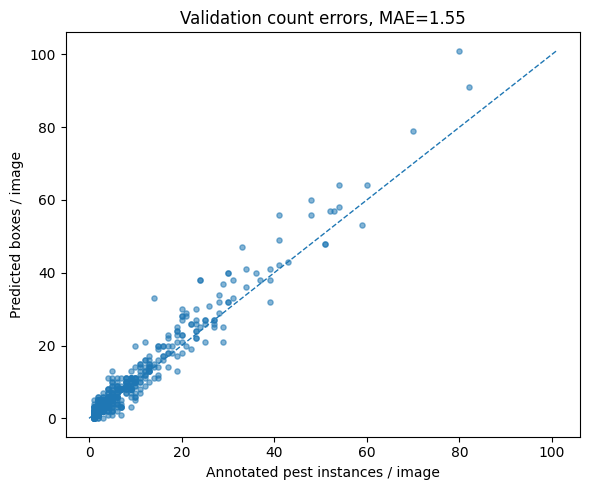

In [10]:
# MAE/RMSE are object-count proxy metrics on validation annotations, NOT unbiased farm population estimates.
# Compute per-image counts at declared confidence 0.25, not tuned on val after inspection.
CONF=float(CONFIG['conf_threshold']);IOU=float(CONFIG['iou_threshold'])
val_img_paths=sorted((YOLO_DATA/'images'/'val').glob('*'))
assert len(val_img_paths)==len(records['val'])
count_rows=[]
for start in range(0,len(val_img_paths),16):
    group=val_img_paths[start:start+16]
    res=best.predict(source=[str(p) for p in group],imgsz=CONFIG['imgsz'],conf=CONF,iou=IOU,device=0,verbose=False)
    assert len(res)==len(group)
    for image_path,pred in zip(group,res):
        true_file=YOLO_DATA/'labels'/'val'/(image_path.stem+'.txt')
        true_counts=Counter(int(line.split()[0]) for line in true_file.read_text().splitlines() if line.strip())
        pred_counts=Counter(int(v) for v in pred.boxes.cls.cpu().numpy().astype(int).tolist())
        count_rows.append({'image':str(image_path.name),'gt_total':sum(true_counts.values()),'pred_total':sum(pred_counts.values()),
                           'gt_class_counts':json.dumps(dict(true_counts),sort_keys=True),
                           'pred_class_counts':json.dumps(dict(pred_counts),sort_keys=True)})
count_df=pd.DataFrame(count_rows);count_df['signed_error']=count_df.pred_total-count_df.gt_total
count_df['absolute_error']=count_df.signed_error.abs()
assert len(count_df)==len(val_img_paths)
count_df.to_csv(REPORTS/'validation_count_per_image.csv',index=False)
mae=float(count_df.absolute_error.mean());rmse=float(np.sqrt(np.mean(np.square(count_df.signed_error))))
exact=float((count_df.signed_error==0).mean())
count_metrics={'threshold_conf':CONF,'threshold_iou':IOU,'validation_images':len(count_df),
               'total_count_MAE':mae,'total_count_RMSE':rmse,'exact_total_count_fraction':exact,
               'limitation':'Counts are boxes detected against annotated boxes, not real-world pest census'}
(REPORTS/'validation_count_metrics.json').write_text(json.dumps(count_metrics,indent=2),encoding='utf8')
print(json.dumps(count_metrics,indent=2))
fig,ax=plt.subplots(figsize=(6,5));ax.scatter(count_df.gt_total,count_df.pred_total,alpha=.55,s=14)
lim=max(count_df.gt_total.max(),count_df.pred_total.max(),1);ax.plot([0,lim],[0,lim],'--',linewidth=1)
ax.set(xlabel='Annotated pest instances / image',ylabel='Predicted boxes / image',title=f'Validation count errors, MAE={mae:.2f}')
fig.tight_layout();fig.savefig(PLOTS/'count_scatter.png',dpi=140);plt.show();plt.close(fig)


## 9 — Qualitative demo: photo → pest boxes + counts (held-out validation images)

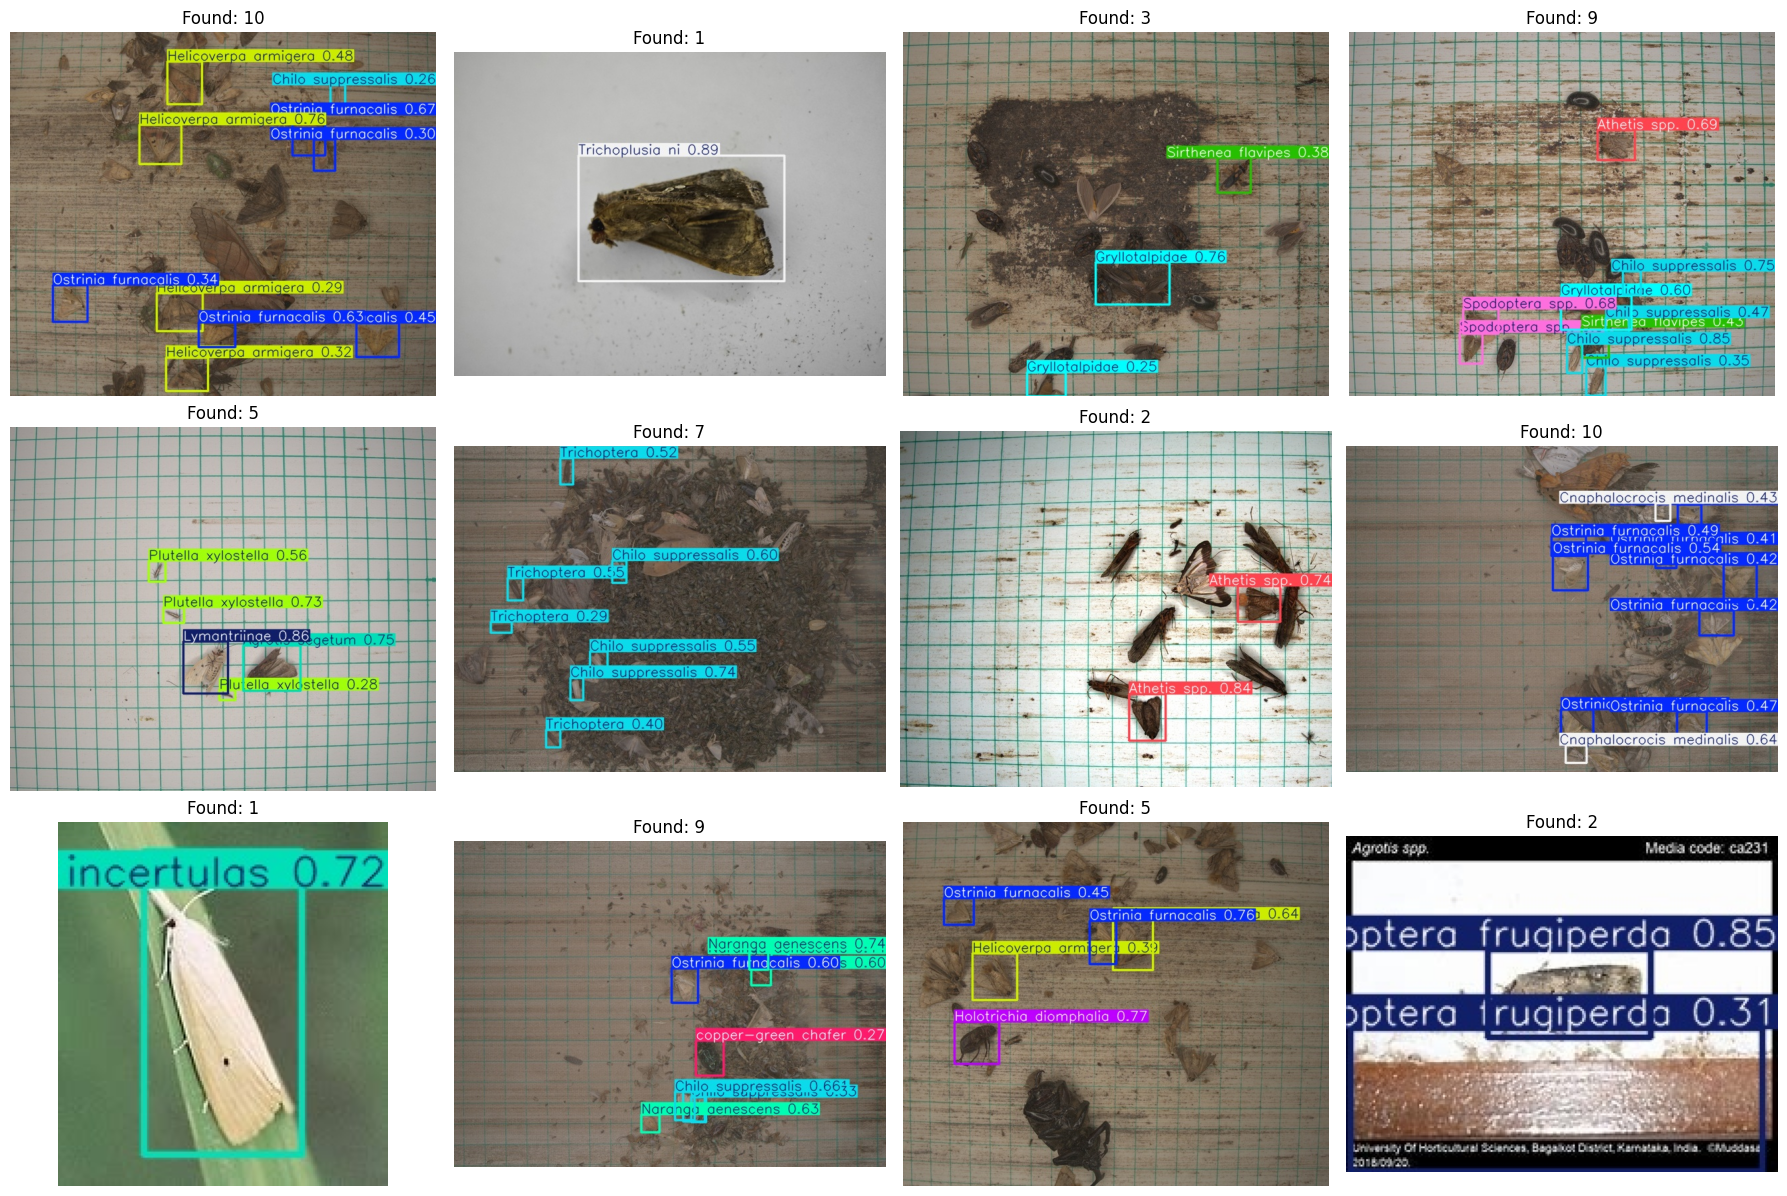

In [11]:
# 12 deterministic examples; chosen before inspecting model quality, not cherry-picked successes.
examples=random.Random(SEED+1).sample(val_img_paths,min(12,len(val_img_paths)))
rows=[]
for i,p in enumerate(examples):
    pred=best.predict(str(p),imgsz=CONFIG['imgsz'],conf=CONF,iou=IOU,device=0,verbose=False)[0]
    shown=pred.plot()
    outfile=DEMO/f'example_{i:02d}.jpg'
    assert cv2.imwrite(str(outfile),shown)
    count=Counter(int(v) for v in pred.boxes.cls.cpu().numpy().astype(int).tolist())
    rows.append({'sample_image':p.name,'output':outfile.name,'total_predicted':sum(count.values()),
                 'counts_per_species':json.dumps({names[k]:v for k,v in count.items()},ensure_ascii=False)})
examples_df=pd.DataFrame(rows);examples_df.to_csv(DEMO/'example_predictions.csv',index=False)
fig,axes=plt.subplots(3,4,figsize=(18,12));axes=axes.ravel()
for ax,row in zip(axes,rows):
    ax.imshow(cv2.cvtColor(cv2.imread(str(DEMO/row['output'])),cv2.COLOR_BGR2RGB))
    ax.set_title(f'Found: {row["total_predicted"]}');ax.axis('off')
for ax in axes[len(rows):]:ax.axis('off')
fig.tight_layout();fig.savefig(PLOTS/'demo_detection_grid.png',dpi=120);plt.show();plt.close(fig)


## 10 — Export optional ONNX, model card, run evidence & small results ZIP

In [12]:
# ONNX export is optional; best.pt always saved. Export failure must be documented rather than fabricated.
onnx_status={'attempted':True,'success':False}
try:
    onnx_path=best.export(format='onnx',imgsz=CONFIG['imgsz'],simplify=False,opset=12)
    onnx_path=Path(onnx_path)
    assert onnx_path.is_file() and onnx_path.stat().st_size>1_000_000
    shutil.copy2(onnx_path,MODELS/'best.onnx')
    onnx_status.update(success=True,filename='models/best.onnx')
except Exception as exc:
    onnx_status['error']=repr(exc)
    print('[WARN] ONNX export optional failure:',repr(exc))
(REPORTS/'onnx_export.json').write_text(json.dumps(onnx_status,indent=2),encoding='utf8')

card={
 'project':'Day 32/100 — RicePest Spotter','purpose':'Visual pest localization and annotated-box counting in still photographs',
 'model':'YOLO11 nano with official pretrained weights; 30 source category IDs kept distinct',
 'source':'https://github.com/kkb20334-lang/RicePest-30',
 'source_license':'CC BY-NC 4.0; noncommercial research use. Check original redistribution conditions.',
 'dataset_kaggle_input':str(SOURCE),'data_summary':summary,
 'category_duplicate_name_warning':duplicate_names,'class_mapping_csv':'audit/class_id_mapping.csv',
 'validation_metrics':scores,'validation_count_metrics':count_metrics,
 'preprocessing':'COCO bbox normalized to YOLO xywh using source image sizes, no manual label merging',
 'split_policy':'Source train/val assignments preserved; V3 eligible subset excludes >2% aspect mismatch images and linked annotations; exact cross-split SHA256 checked',
 'known_limitations':['No independent test split','Validation may not represent unseen farms, sensors, or growing seasons',
    'Source includes field, web, and lab imagery; domain shift','Class names duplicated by source ID; ambiguous species identity',
    '300 unsafe aspect-ratio images (per V2 log) are excluded, not corrected; check current audit for exact counts','Near-duplicate audit is not comprehensive','Class-imbalanced small and dense objects','False negatives bias counts',
    'Inference confidence is not a calibrated probability','Not a crop disease diagnosis or whole-field pest census'],
 'release_status':'Exploratory academic MVP; not production-certified',
 'model_file':'models/best.pt','onnx':onnx_status}
(REPORTS/'MODEL_CARD.json').write_text(json.dumps(card,indent=2,ensure_ascii=False),encoding='utf8')
(AUDIT/'environment.json').write_text(json.dumps({'python':sys.version,'torch':torch.__version__,'ultralytics':importlib.metadata.version('ultralytics'),'seed':SEED,'configuration':CONFIG},indent=2),encoding='utf8')
README=f"""# RicePest Spotter — Day 32/100

Object detection and **visible annotated-box counting**; not an exhaustive insect population census.

Dataset: https://github.com/kkb20334-lang/RicePest-30 — research/noncommercial CC BY-NC 4.0 conditions.
Kaggle input: {SOURCE}

Training: official pretrained {CONFIG['weights']}, seed {SEED}, validation-selected best checkpoint, {CONFIG['epochs']} max epochs with early stopping.
No held-out test provided; all reported metrics are validation only. Unsafe aspect-ratio images and their annotations are excluded rather than mapped speculatively; see audit/eligibility_counts.csv and audit/excluded_source_images.csv.

Validation: precision {scores['precision']:.4f}, recall {scores['recall']:.4f}, mAP50 {scores['mAP50']:.4f}, mAP50:95 {scores['mAP50_95']:.4f}.
Validation box-count MAE {mae:.4f}, RMSE {rmse:.4f}, conf={CONF}.

Source COCO category IDs preserved (see class mapping); duplicate species display names not automatically merged.
Exact SHA256 train-val image overlap checked (0) on eligible subset; near-duplicate risk remains untested. Source image exclusions and removed annotations are documented in audit/.

Output: models/best.pt, optional best.onnx, reports/, audit/, plots/, demo/, training history.
Original images intentionally excluded from ZIP to limit source redistribution.
"""
(WORK/'README.md').write_text(README,encoding='utf8')
# Preserve training history and plots without packing the entire dataset or redundant giant checkpoints.
import zipfile
ARCHIVE=Path('/kaggle/working/Day32_RicePest_Spotter_Results.zip')
include_dirs=[AUDIT,REPORTS,PLOTS,DEMO,MODELS]
with zipfile.ZipFile(ARCHIVE,'w',zipfile.ZIP_DEFLATED,compresslevel=5,allowZip64=True) as z:
    z.write(WORK/'README.md','README.md')
    for folder in include_dirs:
        for f in sorted(folder.rglob('*')):
            if f.is_file():z.write(f,f.relative_to(WORK).as_posix())
    for f in sorted(RUN_DIR.glob('*')):
        if f.is_file() and f.suffix.lower() in {'.csv','.yaml','.png','.jpg'}:
            z.write(f,('training_history/'+f.name))
with zipfile.ZipFile(ARCHIVE) as z:
    bad=z.testzip();assert bad is None,f'CRC failure: {bad}'
    print('[ZIP CRC PASS]',ARCHIVE,'size MiB',round(ARCHIVE.stat().st_size/1024**2,2),'files',len(z.namelist()))
assert (MODELS/'best.pt').is_file() and (REPORTS/'validation_metrics.json').is_file()
print('[COMPLETE] Day 32 — metrics generated from actual model execution. Save Version on Kaggle.')


Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,604,098 parameters, 0 gradients, 6.5 GFLOPs

PyTorch: starting from '/kaggle/working/Day32_RicePest_Spotter/models/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 34, 8400) (5.3 MB)

ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: export success ✅ 1.2s, saved as '/kaggle/working/Day32_RicePest_Spotter/models/best.onnx' (10.2 MB)

Export complete (1.6s)
Results saved to /kaggle/working/Day32_RicePest_Spotter/models/best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/Day32_RicePest_Spotter/models/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/Day32_RicePest_Spotter/models/best.onnx imgsz=640 data=/kaggle/working/Day32_RicePest_Spotter/yol

## Final acceptance checklist

- [ ] Both COCO JSONs are discovered and train/val image paths resolve to the uploaded Kaggle input.
- [ ] 30 **source category IDs** mapped 1:1 to 30 YOLO IDs, with duplicate display names disambiguated.
- [ ] Every image verified, exact cross-split SHA256 intersection zero; **near-duplicate audit still outstanding**.
- [ ] COCO → YOLO conversion audited; no dropped/ignored boxes.
- [ ] Real training completed; `models/best.pt` exists.
- [ ] Real validation mAP50, mAP50–95, precision, recall, per-class AP and count error saved.
- [ ] Qualitative examples, model card, environment, train history included in CRC-checked ZIP.
- [ ] No claims about held-out test accuracy, diagnosis, full-field counts, or production reliability.

**Reminder:** if a data assertion fails, inspect the audit—notebook intentionally stops instead of silently inventing a clean dataset. Keep the original dataset private unless redistribution is allowed.